**PM-KUSUM Solar Battery Dispatch — Bilevel Model**

This notebook implements the two-level optimization model described in our project plan:
- **Lower level (SP1):** a single household minimizes its daily electricity cost by choosing when to charge/discharge its battery, import from the grid, or feed surplus PV back to the grid.
- **Upper level (SP2):** the DISCOM chooses the incentive rate `lambda_inc` (Rs/kWh paid for peak-hour battery discharge). Because the upper level has only one decision variable with a natural range, we solve it by **parametric enumeration** over a grid of candidate values.

This Python model is exactly equivalent to the Excel workbook (HH_Dispatch sheet + DISCOM_Sweep sheet).

In [1]:
%pip install gurobipy

   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ------------------------ --------------- 6.8/11.2 MB 37.2 MB/s eta 0:00:01
   ---------------------------------------- 11.2/11.2 MB 35.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from gurobipy import Model, GRB, quicksum
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### 1. Parameters (from Parameters sheet)

In [3]:
# Battery & PV specs (MNRE PM-KUSUM standard, IRENA 2023)
P_pv        = 2      # rooftop solar capacity (kW)
E_bat       = 4      # battery capacity (kWh)
SOC_min     = 0.15   # minimum state-of-charge fraction
P_ch        = 2      # max charge rate (kWh per hour)
P_dis       = 2      # max discharge rate (kWh per hour)
SOC_init    = 2      # battery charge at hour 0 (kWh)
G_max       = 3      # max grid import/export rate (kW)

# Tariffs (RUVN 2023 ToU schedule, JVVNL 2025 feed-in)
lambda_feed = 3.26   # feed-in tariff for surplus PV exported (Rs/kWh)

# DISCOM coordination parameters (plan §3.3)
B_incentive = 30     # max daily incentive budget (Rs/day)
peak_start  = 18     # peak window start hour (0-indexed, so peak is t=18..21)
peak_end    = 21     # peak window end hour (inclusive)

# Household daily demand (NITI Aayog 2021 — HH01 residential)
HH_daily_demand = 3.2   # kWh/day

### 2. Profiles (from Profiles sheet)

In [4]:
T = 24                    # planning horizon: 24 hours
hours = range(T)          # t = 0..23  (corresponds to Excel t = 1..24)

# PV output per hour in kWh (NREL PVWatts, Jaipur, scaled by P_pv)
pv_output = np.array([0, 0, 0, 0, 0, 0.024, 0.17, 0.44, 0.78, 1.07, 1.31, 1.476,
                      1.53, 1.476, 1.31, 1.07, 0.78, 0.44, 0.12, 0, 0, 0, 0, 0])

# Grid availability a_t (1 = grid up, 0 = load-shedding). PRAYAS ESMI Rajasthan 2023
a_t = np.array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
                0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1])

# Time-of-use grid tariff in Rs/kWh (RUVN 2023)
tariff = np.array([4.5]*12 + [5.5, 5.5] + [4.5]*4 + [7.0]*4 + [4.5]*2)

# Household demand shape (normalized daily shape from NITI Aayog 2021)
demand_shape = np.array([0.05, 0.04, 0.04, 0.04, 0.05, 0.08, 0.12, 0.16, 0.20, 0.18, 0.16, 0.15,
                         0.20, 0.18, 0.14, 0.12, 0.13, 0.16, 0.35, 0.38, 0.32, 0.25, 0.18, 0.12])

# Scale the demand shape to match the household's daily consumption
demand = demand_shape * (HH_daily_demand / demand_shape.sum())

# Set of peak hours for incentive payment
peak_hours = list(range(peak_start, peak_end + 1))    # t = 18..21

### 3. Lower-level model: household battery dispatch LP

For a given incentive rate `lambda_inc`, the household solves:
$$\min \;\; \sum_t \lambda_t \cdot g_t \;-\; \lambda_{inc} \sum_{t \in \text{Peak}} dis_t \;-\; \lambda_{feed} \sum_t feed_t$$

Decision variables at each hour: `ch`, `dis`, `g`, `feed` (all ≥ 0). State variable: `s` (SOC).

In [5]:
def solve_household_LP(lambda_inc, verbose=False):
    """Solve the household dispatch LP for a given incentive rate.
    Returns: (objective value, dict of optimal decision arrays)."""

    m = Model('HH_Dispatch')
    if not verbose:
        m.setParam('OutputFlag', 0)

    # decision variables (one per hour, non-negative by default in Gurobi)
    ch   = m.addVars(T, name='ch')       # battery charge (kWh)
    dis  = m.addVars(T, name='dis')      # battery discharge (kWh)
    g    = m.addVars(T, name='g')        # grid import (kWh)
    feed = m.addVars(T, name='feed')     # PV export to grid (kWh)
    s    = m.addVars(T, name='s')        # battery SOC at end of hour t (kWh)

    # objective: grid cost - incentive revenue - feed-in revenue
    m.setObjective(
        quicksum(tariff[t] * g[t] for t in hours)
        - lambda_inc * quicksum(dis[t] for t in peak_hours)
        - lambda_feed * quicksum(feed[t] for t in hours),
        GRB.MINIMIZE
    )

    # energy balance: PV + discharge + grid import = demand + charge + feed-in
    m.addConstrs((
        pv_output[t] + dis[t] + g[t] == demand[t] + ch[t] + feed[t]
        for t in hours
    ), name='balance')

    # SOC dynamics: s_t = s_{t-1} + ch_t - dis_t
    m.addConstr(s[0] == SOC_init + ch[0] - dis[0], name='soc_init')
    m.addConstrs((
        s[t] == s[t-1] + ch[t] - dis[t] for t in range(1, T)
    ), name='soc_dynamics')

    # SOC bounds: SOC_min * E_bat <= s_t <= E_bat
    m.addConstrs((s[t] >= SOC_min * E_bat for t in hours), name='soc_lower')
    m.addConstrs((s[t] <= E_bat           for t in hours), name='soc_upper')

    # charge / discharge rate limits
    m.addConstrs((ch[t]  <= P_ch  for t in hours), name='ch_limit')
    m.addConstrs((dis[t] <= P_dis for t in hours), name='dis_limit')

    # grid import and feed-in only when grid is available (a_t = 1)
    m.addConstrs((g[t]    <= G_max * a_t[t] for t in hours), name='g_avail')
    m.addConstrs((feed[t] <= G_max * a_t[t] for t in hours), name='feed_avail')

    m.optimize()

    # extract optimal values into numpy arrays
    solution = {
        'ch':   np.array([ch[t].X   for t in hours]),
        'dis':  np.array([dis[t].X  for t in hours]),
        'g':    np.array([g[t].X    for t in hours]),
        'feed': np.array([feed[t].X for t in hours]),
        's':    np.array([s[t].X    for t in hours]),
    }
    return m.ObjVal, solution

### 4. Solve the lower level for one specific lambda_inc

Try `lambda_inc = 1.5` to match the Excel v6 test case.

In [6]:
lambda_inc_test = 1.5
obj, sol = solve_household_LP(lambda_inc_test)

print(f'Lower-level optimal objective (net daily cost): {obj:.2f} Rs')
print(f'Total peak discharge (t=19-22): {sol["dis"][peak_hours].sum():.2f} kWh')
print(f'Total feed-in energy:           {sol["feed"].sum():.2f} kWh')
print(f'Total grid import:              {sol["g"].sum():.2f} kWh')

Restricted license - for non-production use only - expires 2027-11-29
Lower-level optimal objective (net daily cost): -45.24 Rs
Total peak discharge (t=19-22): 8.00 kWh
Total feed-in energy:           10.20 kWh
Total grid import:              0.00 kWh


In [7]:
# display the hourly dispatch schedule
pd.DataFrame({
    'Hour':     [t+1 for t in hours],
    'PV':       pv_output,
    'Demand':   demand.round(3),
    'a_t':      a_t,
    'ch':       sol['ch'].round(3),
    'dis':      sol['dis'].round(3),
    'g':        sol['g'].round(3),
    'feed':     sol['feed'].round(3),
    'SOC':      sol['s'].round(3),
}).set_index('Hour')

,PV,Demand,a_t,ch,dis,g,feed,SOC
Hour,,,,,,,,
1,0.000,0.042,1,0.000,0.042,0.0,0.000,1.958
2,0.000,0.034,1,0.000,0.034,0.0,0.000,1.924
3,0.000,0.034,1,1.966,2.000,0.0,0.000,1.891
4,0.000,0.034,1,1.809,2.000,0.0,0.157,1.700
5,0.000,0.042,1,1.958,2.000,0.0,0.000,1.658
6,0.024,0.067,1,1.957,2.000,0.0,0.000,1.614
7,0.170,0.101,1,0.069,0.000,0.0,0.000,1.683
8,0.440,0.135,1,0.305,0.000,0.0,0.000,1.988
9,0.780,0.168,1,0.612,0.000,0.0,0.000,2.600


### 5. Upper-level model: DISCOM coordination via parametric enumeration

We sweep `lambda_inc` across 12 candidate values and record each household response. The optimal rate is the one that maximizes feeder peak discharge while staying within the DISCOM budget.

In [8]:
lambda_grid = [0, 0.01, 0.2, 0.5, 1, 2, 3, 4, 5, 6, 7, 8]

rows = []
for lam in lambda_grid:
    obj, sol = solve_household_LP(lam)
    peak_dis    = sol['dis'][peak_hours].sum()
    budget_used = lam * peak_dis
    rows.append({
        'lambda_inc':   lam,
        'HH_cost':      round(obj, 2),
        'Peak_Disch':   round(peak_dis, 3),
        'Budget_Used':  round(budget_used, 2),
        'Within_Budget': budget_used <= B_incentive,
    })

sweep = pd.DataFrame(rows)
sweep

,lambda_inc,HH_cost,Peak_Disch,Budget_Used,Within_Budget
0,0.00,-33.24,4.48,0.00,True
1,0.01,-33.32,8.00,0.08,True
2,0.20,-34.84,8.00,1.60,True
3,0.50,-37.24,8.00,4.00,True
4,1.00,-41.24,8.00,8.00,True
5,2.00,-49.24,8.00,16.00,True
6,3.00,-57.24,8.00,24.00,True
7,4.00,-65.24,8.00,32.00,False
8,5.00,-73.24,8.00,40.00,False
9,6.00,-81.24,8.00,48.00,False


In [9]:
# DISCOM's optimal choice: the highest lambda_inc that stays within budget
feasible = sweep[sweep['Within_Budget']]
optimal  = feasible.loc[feasible['HH_cost'].idxmin()]

print(f'Optimal lambda_inc (within budget, min HH cost): {optimal["lambda_inc"]} Rs/kWh')
print(f'  Peak discharge: {optimal["Peak_Disch"]} kWh')
print(f'  Budget used:    {optimal["Budget_Used"]} Rs (limit = {B_incentive} Rs)')

Optimal lambda_inc (within budget, min HH cost): 3.0 Rs/kWh
  Peak discharge: 8.0 kWh
  Budget used:    24.0 Rs (limit = 30 Rs)


### 6. Visualization: Pareto frontier

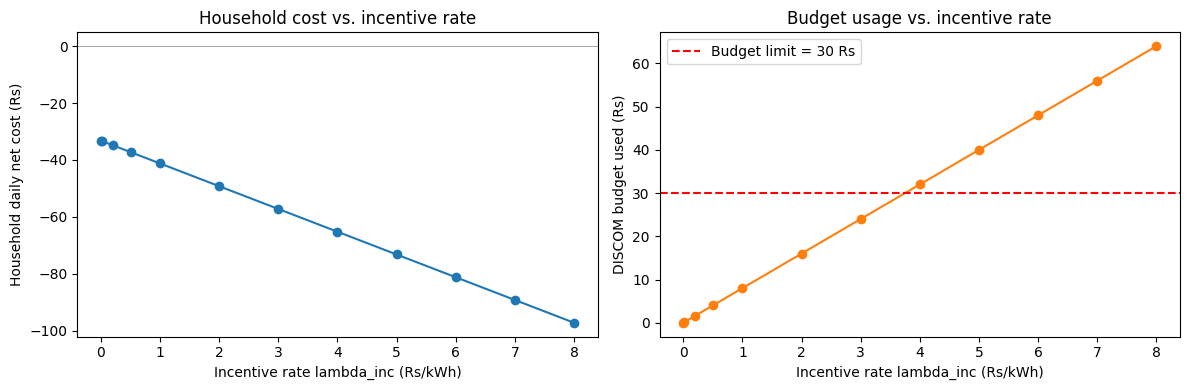

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left: household cost vs incentive rate
axes[0].plot(sweep['lambda_inc'], sweep['HH_cost'], marker='o')
axes[0].set_xlabel('Incentive rate lambda_inc (Rs/kWh)')
axes[0].set_ylabel('Household daily net cost (Rs)')
axes[0].set_title('Household cost vs. incentive rate')
axes[0].axhline(0, color='gray', linewidth=0.5)

# right: budget used vs incentive rate, with budget line
axes[1].plot(sweep['lambda_inc'], sweep['Budget_Used'], marker='o', color='C1')
axes[1].axhline(B_incentive, color='red', linestyle='--', label=f'Budget limit = {B_incentive} Rs')
axes[1].set_xlabel('Incentive rate lambda_inc (Rs/kWh)')
axes[1].set_ylabel('DISCOM budget used (Rs)')
axes[1].set_title('Budget usage vs. incentive rate')
axes[1].legend()

plt.tight_layout()
plt.show()